# Week 2 · Task 3 — Train a classifier

Can we predict whether someone will return to an app the next day? In this exercise, each simulated session has three features: time spent, screens visited, and taps. The label is 1 if the simulated user returned and 0 otherwise.

From the project root, launch JupyterLab with `uv run --locked --with torch --with matplotlib jupyter lab`. Open this notebook in that environment and run its cells in order.

## 1. Create examples and split them

`X` is a table with one row per session and three columns. The numbers represent standardized features, so negative values mean below average. `y` has one label per row. A rule with some random noise creates the labels. For example, a session with features `[1, 0, 0]` and zero noise gets a score of 1.5 from the rule, so its label is 1.

Shuffle the row indices once. The model learns from 210 training sessions. We check progress on 45 separate validation sessions. We reserve 45 test sessions for the final model after comparing settings in Task 4.

In [ ]:
# Import PyTorch for tensors and automatic gradients.
import torch
# Import PyTorch neural network layers and losses.
from torch import nn

# Create a seeded random generator for reproducible data and splits.
rng = torch.Generator().manual_seed(42)

# Create 300 simulated sessions, each with three standardized features.
X = torch.randn(300, 3, generator=rng)
# Add random variation to make labels less perfectly predictable.
noise = 0.3 * torch.randn(300, generator=rng)
# Apply the hidden labeling rule and convert True or False to 1 or 0.
y = (1.5 * X[:, 0] + X[:, 1] - 0.5 * X[:, 2] + noise > 0).float()

# Shuffle row indices and reserve separate training, validation, and test groups.
train, val, test = torch.randperm(len(X), generator=rng).split([210, 45, 45])

# Display the number of sessions and labels.
print("Features:", X.shape, "| Labels:", y.shape)
# Display the sizes of the three data splits.
print(f"Train: {len(train)} | Validation: {len(val)} | Test: {len(test)}")

## 2. Teach the model with the training sessions

`nn.Linear(3, 1)` uses three trainable weights and one bias to produce one raw score per session. The model starts with random parameters and learns from the feature rows and labels.

Each epoch processes the whole training split and takes one optimizer step:

1. Clear the gradients from the previous epoch.
2. Run the forward pass and calculate the loss with `BCEWithLogitsLoss`.
3. Use `loss.backward()` to compute each parameter's gradient.
4. Use `optimizer.step()` to update the parameters. SGD subtracts the learning rate times the gradient, just like the single weight update in Task 2.

We report training and validation loss after the same update, without computing gradients for either measurement.

In [ ]:
# Reset the seed so model weights start reproducibly.
torch.manual_seed(42)

# Create a trainable layer mapping three features to one score.
model = nn.Linear(3, 1)
# Choose binary classification loss that accepts raw scores.
loss_fn = nn.BCEWithLogitsLoss()
# Create an optimizer that updates parameters using a 0.1 step size.
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

# Repeat training for 100 full passes over the training split.
for epoch in range(1, 101):
    # Clear gradients carried over from the previous update.
    optimizer.zero_grad()

    # Remove the final dimension so scores and labels both have shape (210,).
    # Predict training scores and remove the last one-element dimension.
    scores = model(X[train]).squeeze(-1)
    # Measure prediction error against the training labels.
    loss = loss_fn(scores, y[train])
    # Ask autograd for each parameter's gradient.
    loss.backward()
    # Move the model parameters using their gradients.
    optimizer.step()

    # Report progress at four selected epochs.
    if epoch in (1, 25, 50, 100):
        # Measure results without building a gradient graph.
        with torch.no_grad():
            # Measure error on the training split after the update.
            train_loss = loss_fn(model(X[train]).squeeze(-1), y[train])
            # Measure error on unseen validation sessions.
            val_loss = loss_fn(model(X[val]).squeeze(-1), y[val])

        # Print a multi-line formatted progress message.
        print(
            # Show the current epoch number.
            f"Epoch {epoch:3d} | "
            # Show the current training loss.
            f"Train loss: {train_loss.item():.3f} | "
            # Show the current validation loss.
            f"Validation loss: {val_loss.item():.3f}"
        )

## 3. Compare with a simple baseline

A raw score of 0 corresponds to a 50% probability after applying the sigmoid. Predict that the user returns when the score is 0 or higher.

The baseline always predicts the most common label in the training split. Score both methods on the same validation sessions, then compare their accuracy.

In [ ]:
# Measure results without building a gradient graph.
with torch.no_grad():
    # Predict raw scores for the validation examples.
    val_scores = model(X[val]).squeeze(-1)
    # Classify a nonnegative logit as a return prediction.
    predictions = val_scores >= 0
    # Convert validation labels to booleans for comparison.
    val_labels = y[val].bool()
    # Calculate the fraction of correct model predictions.
    model_accuracy = (predictions == val_labels).float().mean()

    # Find the most common training label for a simple baseline.
    majority_label = y[train].mean() >= 0.5
    # Calculate the baseline's accuracy on the same validation sessions.
    baseline_accuracy = (majority_label == val_labels).float().mean()

# Display model accuracy as a percentage.
print(f"Validation accuracy: {model_accuracy.item():.1%}")
# Display baseline accuracy as a percentage.
print(f"Baseline accuracy:   {baseline_accuracy.item():.1%}")

## What to record

- Compare the training loss at epochs 1 and 100.
- Record the validation accuracy for the classifier and the baseline.
- In Task 4, reuse the same split and the same parameter initialization when you compare learning rates.

## Week 2 · Task 4 — Compare learning rates

Train the same classifier for 100 epochs with learning rates of 0.01, 0.1, and 1.0. Each run uses the same train and validation splits and starts with the same weights. Record both losses after each optimizer step.

Select the learning rate with the lowest validation loss at epoch 100. The test set is reserved for the final evaluation.

In [5]:
# Train a fresh model at a requested learning rate and collect its losses.
def compare_run(learning_rate):
    # Reset the seed so model weights start reproducibly.
    torch.manual_seed(42)
    # Create a fresh model with the same starting seed for a fair comparison.
    candidate = nn.Linear(3, 1)
    # Assign this run its requested learning rate.
    candidate_optimizer = torch.optim.SGD(candidate.parameters(), lr=learning_rate)
    # Prepare lists to store one loss per epoch for each split.
    train_losses, val_losses = [], []

    # Perform 100 parameter updates for this learning rate.
    for _ in range(100):
        # Clear gradients before calculating this epoch's loss.
        candidate_optimizer.zero_grad()
        # Calculate training scores with this candidate model.
        train_scores = candidate(X[train]).squeeze(-1)
        # Measure this candidate's error on training labels.
        loss = loss_fn(train_scores, y[train])
        # Ask autograd for each parameter's gradient.
        loss.backward()
        # Apply one parameter update for the candidate.
        candidate_optimizer.step()

        # Measure both losses with the same updated weights.
        # Measure results without building a gradient graph.
        with torch.no_grad():
            # Calculate training scores with this candidate model.
            train_scores = candidate(X[train]).squeeze(-1)
            # Calculate scores for validation examples.
            val_scores = candidate(X[val]).squeeze(-1)
            # Record training loss after the update.
            train_losses.append(loss_fn(train_scores, y[train]).item())
            # Record validation loss after the update.
            val_losses.append(loss_fn(val_scores, y[val]).item())

    # Return both curves for plotting and comparison.
    return train_losses, val_losses


# Run the experiment at three learning rates.
results = {rate: compare_run(rate) for rate in (0.01, 0.1, 1.0)}

Matplotlib is building the font cache; this may take a moment.


lr=0.01 | Epoch 100 train loss: 0.411 | validation loss: 0.487
lr=0.1 | Epoch 100 train loss: 0.231 | validation loss: 0.306
lr=1 | Epoch 100 train loss: 0.111 | validation loss: 0.175


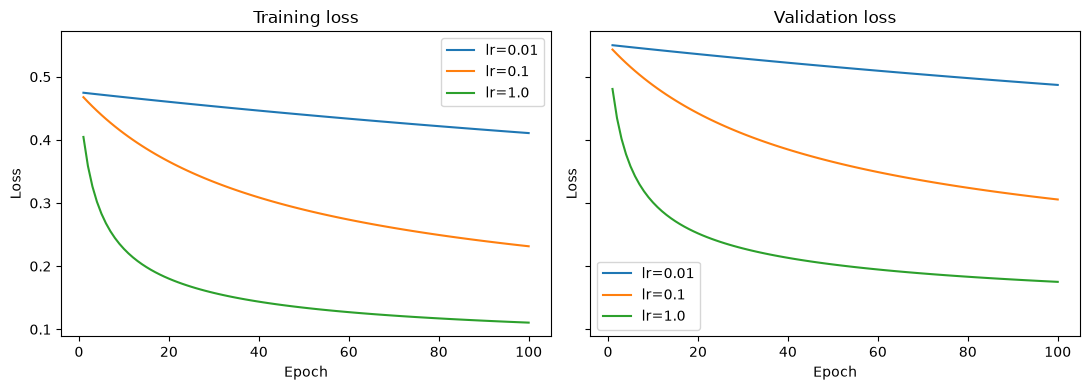

Lowest validation loss at epoch 100: lr=1


In [7]:
# Import Matplotlib for the two loss charts.
import matplotlib.pyplot as plt

# Make side-by-side charts with a common vertical scale.
fig, (train_ax, val_ax) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
# Create epoch numbers for the horizontal axis.
epochs = range(1, 101)

# Draw curves for each learning rate.
for rate, (train_losses, val_losses) in results.items():
    # Plot this rate's training losses.
    train_ax.plot(epochs, train_losses, label=f"lr={rate}")
    # Plot this rate's validation losses.
    val_ax.plot(epochs, val_losses, label=f"lr={rate}")
    # Print a multi-line formatted progress message.
    print(
        # Report final training loss for this rate.
        f"lr={rate:g} | Epoch 100 train loss: {train_losses[-1]:.3f} | "
        # Report final validation loss for this rate.
        f"validation loss: {val_losses[-1]:.3f}"
    )

# Format both charts the same way.
for ax, title in [(train_ax, "Training loss"), (val_ax, "Validation loss")]:
    # Label the title and both axes.
    ax.set(title=title, xlabel="Epoch", ylabel="Loss")
    # Show which line belongs to each learning rate.
    ax.legend()

# Adjust spacing so labels do not overlap.
fig.tight_layout()
# Display the plots in the notebook.
plt.show()

# Choose the rate with the smallest final validation loss.
best_rate = min(results, key=lambda rate: results[rate][1][-1])
# Display the selected rate.
print(f"Lowest validation loss at epoch 100: lr={best_rate:g}")

Which rate learns fastest in the first few epochs? Which finishes with the lowest validation loss? If training loss keeps falling while validation loss rises, the model is getting better on the training sessions and worse on unseen sessions. In Task 5, use the selected rate to produce a checkpoint.

## Week 2 · Task 5 — Save and reload a checkpoint

Use the learning rate selected from validation loss in Task 4. Start from the same random weights, train for 100 epochs, and save both the learned model parameters and the optimizer settings. Run all previous cells first so `X`, `y`, `train`, `val`, `loss_fn`, and `best_rate` exist.

The checkpoint file is written to the notebook's current working directory. Keep it outside Git if you are just practicing.


In [ ]:
# Import Path for the checkpoint filename.
from pathlib import Path

# Reset the seed so model weights start reproducibly.
torch.manual_seed(42)
# Create a fresh model using the chosen run's starting seed.
chosen_model = nn.Linear(3, 1)
# Set up SGD with the selected learning rate.
chosen_optimizer = torch.optim.SGD(chosen_model.parameters(), lr=best_rate)

# Repeat training for 100 full passes over the training split.
for epoch in range(1, 101):
    # Clear gradients before the next training step.
    chosen_optimizer.zero_grad()
    # Predict the scores for training rows.
    scores = chosen_model(X[train]).squeeze(-1)
    # Measure prediction error against the training labels.
    loss = loss_fn(scores, y[train])
    # Ask autograd for each parameter's gradient.
    loss.backward()
    # Update the chosen model's parameters.
    chosen_optimizer.step()

# Choose where to save the checkpoint.
checkpoint_path = Path("week02_classifier.pt")
# Serialize the completed training state to a file.
torch.save(
    {
        # Remember how many training epochs finished.
        "epoch": epoch,
        # Remember which learning rate was chosen.
        "learning_rate": best_rate,
        # Store learned weights and bias.
        "model_state": chosen_model.state_dict(),
        # Store SGD parameter groups and any optimizer state.
        "optimizer_state": chosen_optimizer.state_dict(),
    },
    # Write the checkpoint to the selected path.
    checkpoint_path,
)
# Display the full path of the saved checkpoint.
print("Saved:", checkpoint_path.resolve())

## Reload into a new model

A fresh `nn.Linear(3, 1)` starts with different weights. Loading the saved `model_state` replaces them with your trained weights. The optimizer's state restores the settings used to train it.

This exercise uses SGD without momentum. Its optimizer state contains the learning rate and parameter groups, with no running momentum values.


In [ ]:
# Load only the saved data and tensors onto the CPU.
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

# Create an empty model with the original architecture.
reloaded_model = nn.Linear(3, 1)
# Create an optimizer attached to that new model.
reloaded_optimizer = torch.optim.SGD(
    # Start it with the saved learning rate.
    reloaded_model.parameters(), lr=checkpoint["learning_rate"]
)
# Replace initial weights with the trained parameters.
reloaded_model.load_state_dict(checkpoint["model_state"])
# Restore optimizer settings and stored state.
reloaded_optimizer.load_state_dict(checkpoint["optimizer_state"])

# Measure results without building a gradient graph.
with torch.no_grad():
    # Predict validation scores using the original model.
    original_scores = chosen_model(X[val])
    # Predict validation scores using the restored model.
    reloaded_scores = reloaded_model(X[val])

# Check that restoring produced the same predictions.
torch.testing.assert_close(original_scores, reloaded_scores)
# Confirm the optimizer recovered the selected rate.
assert reloaded_optimizer.param_groups[0]["lr"] == best_rate

# Show the number of completed epochs stored in the file.
print("Reloaded epoch:", checkpoint["epoch"])
# Show the restored optimizer learning rate.
print("Reloaded learning rate:", reloaded_optimizer.param_groups[0]["lr"])
# Report that the restored model matched its original.
print("Validation predictions match after reload.")